In [1]:
# Clustering and Multidimensional Scaling of Hybrid Similarity Search Results: Application to Illicit Drug Mass Spectra
# Melinda A. Kleczynski, Arun S. Moorthy, Anthony J. Kearsley

# run MDS for many initial configurations 

### User selections

In [2]:
n_trials = 1000       # 1000 trials to produce the results in the manuscript; can lower to decrease run time 
dataset_number = 1    # 1, 2, 3, or 4  (see Table 1)
save_outputs = False  

### Packages

In [3]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd 

from scipy.optimize import least_squares 
from scipy.spatial.distance import pdist, squareform  

from scipy.cluster import hierarchy 
from sklearn.metrics import fowlkes_mallows_score 

### Read data

In [4]:
# initially "unsorted" in the sense that we have not yet chosen the spectrum whose point we are restricting to the x-axis

unsorted_asymmetric_HSS_MFs = pd.read_csv('hitlists\\HSS' + str(dataset_number) + '.csv', header = None).to_numpy()
if np.sum(np.isnan(unsorted_asymmetric_HSS_MFs)) > 0: 
    print('Caution: nan values')
unsorted_HSS_MFs = 0.5*(unsorted_asymmetric_HSS_MFs + np.transpose(unsorted_asymmetric_HSS_MFs))  # symmetrize  
unsorted_Delta = (999 - unsorted_HSS_MFs)/999

unsorted_spectra_keys = pd.read_csv('hitlists\\key' + str(dataset_number) + '.csv', usecols = ['Name', 'NIST Number']) 

n_objects = len(unsorted_spectra_keys)

### Choose spectrum to assign to x-axis and reorder to place right after query spectrum

In [5]:
farthest_spec = int(np.argmax([np.sum(np.abs(unsorted_Delta[:, 0] - unsorted_Delta[:, i])) for i in range(n_objects)]))

In [6]:
other_indices = [i for i in range(1, n_objects) if i != farthest_spec]
for_sorting = [0] + [farthest_spec] + other_indices

In [7]:
Delta = unsorted_Delta[np.ix_(for_sorting, for_sorting)]
spectra_keys = unsorted_spectra_keys.reindex(for_sorting).reset_index(drop = True)

### Functions

In [8]:
# random initializations 

m = n_objects*(n_objects-1)/2 
S = np.sum(np.square(Delta))/2  
sigma = (S/(4*m))**0.5

def get_random_init(seed = None):

    size = 2*n_objects-3  # x and y coordinate for each object, one object at origin, one object on x-axis 

    rng = np.random.default_rng(seed = seed)
    random_vals = rng.normal(size = size)
    random_init = sigma*random_vals 
    
    return random_init 

In [9]:
def vec_to_coords(vec):
    coords = np.zeros((n_objects, 2)) 
    coords[1, 0] = vec[0] 
    coords[2:, :] = vec[1:].reshape((n_objects-2, 2))
    return coords

def get_stress(mds_config, Delta):  # mds_config nxp, Delta nxn

    mds_pdist = squareform(pdist(mds_config, metric = 'euclidean')) 
    return np.sum(np.square(mds_pdist - Delta))/2  

def get_s_stress(mds_config, Delta):  # mds_config nxp, Delta nxn

    mds_pdist = squareform(pdist(mds_config, metric = 'euclidean')) 
    return np.sum(np.square(np.square(mds_pdist) - np.square(Delta)))/2 

def f(v, Delta, n, loss):  # loss = 'STRESS' or loss = 'SSTRESS' 

    X = vec_to_coords(v)

    X_pdist = squareform(pdist(X, metric = 'euclidean')) 

    if loss == 'STRESS':
        rs = X_pdist - Delta
    elif loss == 'SSTRESS':
        rs = np.square(X_pdist) - np.square(Delta)  

    return [rs[i, j] for j in range(n) for i in range(j)] 

### Get cluster labels for original HSS dissimilarities for comparison 

In [10]:
orig_clabels = np.load('TwoStepClusterLabels\\OrigDissimClabels' + str(dataset_number) + '.npy')
n_MDS_clusters = len(np.unique(orig_clabels))

### Compute MDS

In [11]:
# all MDS configurations

stress_vs = np.zeros((n_trials, 2*n_objects-3))
stresses = np.zeros(n_trials)
stress_complete_FMIs = np.zeros(n_trials)
stress_single_FMIs = np.zeros(n_trials)

s_stress_vs = np.zeros((n_trials, 2*n_objects-3))
s_stresses = np.zeros(n_trials)
s_stress_complete_FMIs = np.zeros(n_trials)
s_stress_single_FMIs = np.zeros(n_trials)

for s in range(n_trials): 

    random_IC = get_random_init(s) 

    stress_v = least_squares(f, random_IC, args = [Delta, n_objects, 'STRESS'], method = 'lm').x  
    stress_vs[s, :] = stress_v 
    stresses[s] = get_stress(vec_to_coords(stress_v), Delta)

    s_stress_v = least_squares(f, random_IC, args = [Delta, n_objects, 'SSTRESS'], method = 'lm').x  
    s_stress_vs[s, :] = s_stress_v 
    s_stresses[s] = get_s_stress(vec_to_coords(s_stress_v), Delta)

    ### cluster stress results (we haven't standardized the reflection yet, but that doesn't affect the clusters)

    stress_config = vec_to_coords(stress_v)

    stress_complete_hier = hierarchy.linkage(stress_config, method = 'complete', optimal_ordering = True) 
    stress_complete_clabels = hierarchy.fcluster(stress_complete_hier, n_MDS_clusters, criterion = 'maxclust')
    stress_complete_FMIs[s] = fowlkes_mallows_score(orig_clabels, stress_complete_clabels)

    stress_single_hier = hierarchy.linkage(stress_config, method = 'single', optimal_ordering = True) 
    stress_single_clabels = hierarchy.fcluster(stress_single_hier, n_MDS_clusters, criterion = 'maxclust')
    stress_single_FMIs[s] = fowlkes_mallows_score(orig_clabels, stress_single_clabels)

    ### cluster s_stress results 

    s_stress_config = vec_to_coords(s_stress_v)

    s_stress_complete_hier = hierarchy.linkage(s_stress_config, method = 'complete', optimal_ordering = True) 
    s_stress_complete_clabels = hierarchy.fcluster(s_stress_complete_hier, n_MDS_clusters, criterion = 'maxclust')
    s_stress_complete_FMIs[s] = fowlkes_mallows_score(orig_clabels, s_stress_complete_clabels)

    s_stress_single_hier = hierarchy.linkage(s_stress_config, method = 'single', optimal_ordering = True) 
    s_stress_single_clabels = hierarchy.fcluster(s_stress_single_hier, n_MDS_clusters, criterion = 'maxclust')
    s_stress_single_FMIs[s] = fowlkes_mallows_score(orig_clabels, s_stress_single_clabels)

In [12]:
# best STRESS and SSTRESS 

stress_best_seed = np.argmin(stresses)  
s_stress_best_seed = np.argmin(s_stresses)

In [13]:
final_stress_config = vec_to_coords(stress_vs[stress_best_seed, :]) 
final_s_stress_config = vec_to_coords(s_stress_vs[s_stress_best_seed, :]) 

### Save MDS configurations

In [14]:
if save_outputs:

    suffix = str(dataset_number) + '_'  + str(n_trials) + '.npy'

    # initial configurations

    stress_random_IC = get_random_init(stress_best_seed)
    s_stress_random_IC = get_random_init(s_stress_best_seed)

    np.save('configurations\\stress_initial_' + suffix, stress_random_IC)
    np.save('configurations\\s_stress_initial_' + suffix, s_stress_random_IC)

    # final configurations

    np.save('configurations\\stress_final_' + suffix, final_stress_config)
    np.save('configurations\\s_stress_final_' + suffix, final_s_stress_config)

### Compare configurations

In [15]:
all_FMIs = np.hstack([stress_complete_FMIs, stress_single_FMIs, s_stress_complete_FMIs, s_stress_single_FMIs])

FMI_bins = plt.hist(all_FMIs, bins = 25)[1]
plt.close()

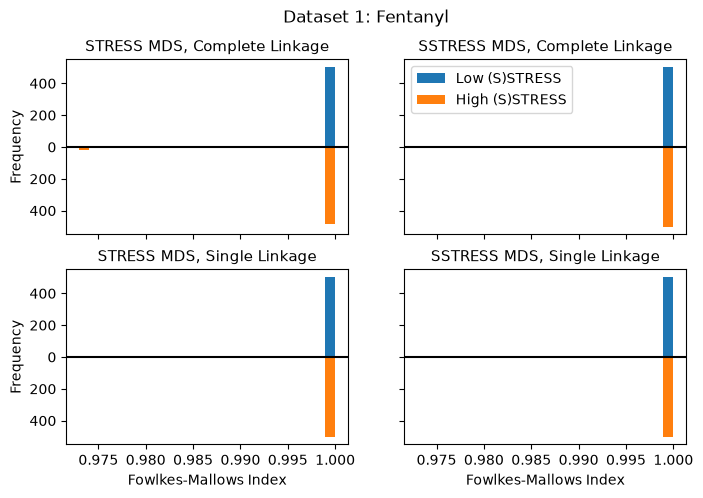

In [16]:
fig, ax = plt.subplots(2, 2, sharex = True, sharey = True, figsize = (8, 5))

### stress

# complete

ax[0, 0].hist(stress_complete_FMIs[stresses < np.median(stresses)], bins = FMI_bins)
ax[0, 0].hist(stress_complete_FMIs[stresses >= np.median(stresses)], bins = FMI_bins, weights = -np.ones_like(stress_complete_FMIs[stresses >= np.median(stresses)]))
ax[0, 0].set_title('STRESS MDS, Complete Linkage', fontsize = 11)

# single

ax[1, 0].hist(stress_single_FMIs[stresses < np.median(stresses)], bins = FMI_bins)
ax[1, 0].hist(stress_single_FMIs[stresses >= np.median(stresses)], bins = FMI_bins, weights = -np.ones_like(stress_single_FMIs[stresses >= np.median(stresses)]))
ax[1, 0].set_title('STRESS MDS, Single Linkage', fontsize = 11)

### s_stress

# complete

ax[0, 1].hist(s_stress_complete_FMIs[s_stresses < np.median(s_stresses)], bins = FMI_bins, label = 'Low (S)STRESS')
ax[0, 1].hist(s_stress_complete_FMIs[s_stresses >= np.median(s_stresses)], bins = FMI_bins, weights = -np.ones_like(s_stress_complete_FMIs[s_stresses >= np.median(s_stresses)]), label = 'High (S)STRESS')
ax[0, 1].set_title('SSTRESS MDS, Complete Linkage', fontsize = 11)
ax[0, 1].legend()

# single

ax[1, 1].hist(s_stress_single_FMIs[s_stresses < np.median(s_stresses)], bins = FMI_bins)
ax[1, 1].hist(s_stress_single_FMIs[s_stresses >= np.median(s_stresses)], bins = FMI_bins, weights = -np.ones_like(s_stress_single_FMIs[s_stresses >= np.median(s_stresses)]))
ax[1, 1].set_title('SSTRESS MDS, Single Linkage', fontsize = 11)

### formatting 

for i in range(2):
    for j in range(2):

        ax[i, j].axhline(0, c = 'k')

        if j == 0:
            ax[i, j].set_yticks([-400, -200, 0, 200, 400], [400, 200, 0, 200, 400])
            ax[i, j].set_ylabel('Frequency')

        if i == 1:
            ax[i, j].set_xlabel('Fowlkes-Mallows Index')

plt.suptitle('Dataset ' + str(dataset_number) + ': ' + spectra_keys['Name'].iloc[0])

plt.show()